In [1]:
#import libraries

import pandas as pd
import numpy as np
import re
import string
import pickle

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
import os
print(os.getcwd())

c:\project data\fyp


In [4]:
# load dataset
import pandas as pd
df = pd.read_csv(
    r"C:\project data\fyp\fake job.csv"
)

print("Dataset Loaded Successfully")


Dataset Loaded Successfully


In [5]:
# data analysis
print("="*50)
print("DATASET INFORMATION")
print("="*50)

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['fraudulent'].value_counts())

DATASET INFORMATION

Shape:
(17880, 18)

Columns:
Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')

Missing Values:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

Class Distribution:
fraudulent
0    17014
1      866
Name: c

In [6]:
# select column 
text_columns = [

    'title',

    'company_profile',

    'description',

    'requirements',

    'benefits'
]

In [7]:
df[text_columns] = df[text_columns].fillna("")

df['combined_text'] = (

    df['title'] + " " +

    df['company_profile'] + " " +

    df['description'] + " " +

    df['requirements'] + " " +

    df['benefits']
)

In [8]:
# data cleaning
def clean_text(text):

    text = str(text).lower()

    text = re.sub(
        r'http\S+',
        '',
        text
    )

    text = re.sub(
        r'www\S+',
        '',
        text
    )

    text = re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text
    )

    text = text.translate(
        str.maketrans(
            '',
            '',
            string.punctuation
        )
    )

    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    return text.strip()

In [9]:
df['combined_text'] = (

    df['combined_text']
    .astype(str)
    .apply(clean_text)
)

In [10]:
#
# Remove Duplicates and Empty Records
df.drop_duplicates(
    inplace=True
)

df.dropna(
    inplace=True
)

df = df[
    df['combined_text'].str.strip() != ""
]

print(df.shape)

(1058, 19)


In [11]:
#Exploratory Data Analysis
#Class Distribution
print(
    df['fraudulent']
    .value_counts()
)

fraudulent
0    950
1    108
Name: count, dtype: int64


In [12]:
#Text Length
df['text_length'] = (

    df['combined_text']
    .apply(len)
)

print(
    df['text_length']
    .describe()
)

count     1058.000000
mean      3036.944234
std       1558.322337
min        160.000000
25%       1943.750000
50%       2802.000000
75%       3819.500000
max      11143.000000
Name: text_length, dtype: float64


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/class_distribution.png'

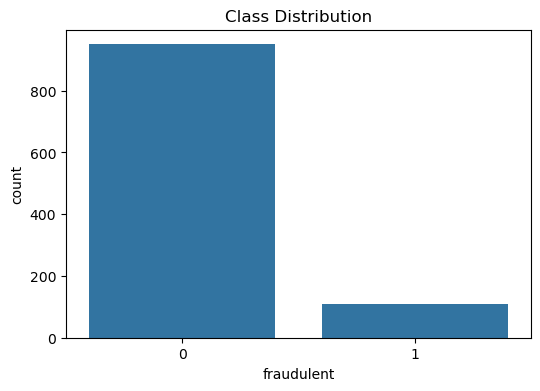

In [13]:
#Visualization
#Class Distribution Chart
plt.figure(figsize=(6,4))

sns.countplot(
    x='fraudulent',
    data=df
)

plt.title(
    "Class Distribution"
)

plt.savefig(
    "outputs/class_distribution.png"
)

plt.show()


In [14]:
#TF-IDF Vectorization
vectorizer = TfidfVectorizer(

    stop_words='english',

    max_features=15000,

    ngram_range=(1,2)
)

X = vectorizer.fit_transform(
    df['combined_text']
)

y = df['fraudulent']

In [15]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

In [16]:
#Logistic Regression
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

In [17]:
#GridSearchCV
param_grid = {

    'C':[0.1,1,10,100],

    'solver':['liblinear']
}
grid = GridSearchCV(

    estimator=log_reg,

    param_grid=param_grid,

    cv=5,

    scoring='f1',

    n_jobs=-1
)
#Train:

grid.fit(
    X_train,
    y_train
)

,estimator,LogisticRegre...max_iter=1000)
,param_grid,"{'C': [0.1, 1, ...], 'solver': ['liblinear']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [18]:
#Get best model
model = grid.best_estimator_

print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'C': 1, 'solver': 'liblinear'}


In [19]:
#Prediction
y_pred = grid.predict(
    X_test
)

In [20]:
#evaluation

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)
print("Accuracy :", accuracy)

print("Precision:", precision)

print("Recall   :", recall)

print("F1 Score :", f1)


Accuracy : 0.9811320754716981
Precision: 0.9090909090909091
Recall   : 0.9090909090909091
F1 Score : 0.9090909090909091


In [21]:
# confusion matrix 
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[188   2]
 [  2  20]]


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/confusion_matrix.png'

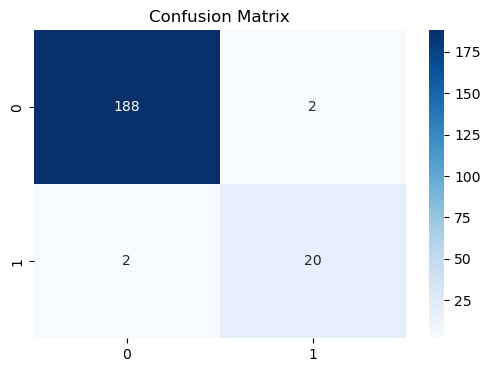

In [22]:
# heatmap

plt.figure(figsize=(6,4))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Blues'
)

plt.title(
    "Confusion Matrix"
)

plt.savefig(
    "outputs/confusion_matrix.png"
)

plt.show()

In [23]:
# Classification Report
print(

    classification_report(

        y_test,

        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       190
           1       0.91      0.91      0.91        22

    accuracy                           0.98       212
   macro avg       0.95      0.95      0.95       212
weighted avg       0.98      0.98      0.98       212



FileNotFoundError: [Errno 2] No such file or directory: 'outputs/metrics.png'

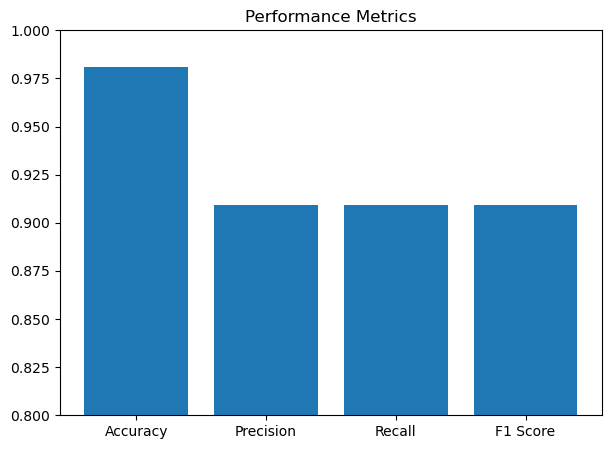

In [24]:
#Metrics Chart
metrics = [

    accuracy,

    precision,

    recall,

    f1
]

names = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1 Score"
]
plt.figure(figsize=(7,5))

plt.bar(
    names,
    metrics
)

plt.ylim(
    0.80,
    1.00
)

plt.title(
    "Performance Metrics"
)

plt.savefig(
    "outputs/metrics.png"
)

plt.show()

In [25]:
import os
import pickle

os.makedirs("models", exist_ok=True)

pickle.dump(
    model,
    open("models/fake_job_model.pkl", "wb")
)

pickle.dump(
    vectorizer,
    open("models/fake_job_vectorizer.pkl", "wb")
)

print("Model Saved Successfully")

Model Saved Successfully


In [26]:
print(model)

LogisticRegression(C=1, class_weight='balanced', max_iter=1000,
                   solver='liblinear')


In [27]:
#load model
import pickle

model = pickle.load(
    open("models/fake_job_model.pkl", "rb")
)

vectorizer = pickle.load(
    open("models/fake_job_vectorizer.pkl", "rb")
)

In [28]:
# again cleaning function
import re
import string

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)

    text = re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text
    )

    text = text.translate(
        str.maketrans(
            '',
            '',
            string.punctuation
        )
    )

    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    return text.strip()

In [29]:
# example
job_text = """
Work from home and earn $5000 per week.
No experience needed.
Immediate hiring.
Send your bank details now.
"""

job_text = clean_text(job_text)

job_vector = vectorizer.transform([job_text])

prediction = model.predict(job_vector)

print(prediction)

[0]


In [30]:
job_text = """
Software Engineer

Requirements:
Bachelor degree in Computer Science.
Experience with Python, SQL, Git and Machine Learning.
Strong communication skills.
"""

job_text = clean_text(job_text)

job_vector = vectorizer.transform([job_text])

prediction = model.predict(job_vector)

print(prediction)

[0]
